# Unsupervised Learning – I
### Clustering • Model Selection • Association Rules • PCA

> **Core question:** Given observations without target labels, how can we find meaningful groupings, judge them, identify co-occurring events, and represent complicated data in fewer dimensions?

## 0. Setup and reproducibility

We use widely available packages already preinstalled in Google Colab: **NumPy, Pandas, Matplotlib, and scikit-learn**. Our short Apriori implementation uses only the Python standard library, so there is no extra package installation or external service.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from IPython.display import display
from itertools import combinations
from collections import Counter

from sklearn.datasets import make_blobs, make_moons, make_circles, load_wine
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'axes.grid': True,
    'grid.alpha': 0.20,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | scikit-learn ready')

Python 3.13.16 | NumPy 2.1.3 | scikit-learn ready


## 1. What is unsupervised learning?

**Supervised learning:** The training data contain an input $X$ and a known target $y$; e.g., learn to predict *spam / not spam*.

**Unsupervised learning:** We observe $X$ but have **no target labels** for training. We try to discover useful structure in the observations.

| Task | Question | Example |
|---|---|---|
| **Clustering** | Which observations resemble one another? | Customer segmentation |
| **Association** | Which items tend to occur together? | Products purchased together |
| **Dimensionality reduction** | Can fewer features preserve useful structure? | 13 features → 2D visualization |


## 2. Clustering: intuition, distance, and types

A **cluster** is a group of observations that are similar under a chosen notion of distance, density, or probability. Different algorithms make different assumptions about cluster shape.

### 2.1 Distance gives one notion of similarity

For two observations $x_i,x_j\in\mathbb{R}^d$, Euclidean distance is

$$d(x_i,x_j)=\sqrt{\sum_{p=1}^{d}(x_{ip}-x_{jp})^2}.$$

**Worked example:** If $A=(1,2)$ and $B=(4,6)$, then $d(A,B)=\sqrt{3^2+4^2}=5$.

**Important:** Features measured on different scales can dominate distances; for example, annual income may overwhelm a 1–5 satisfaction score. Standardization is therefore often useful.

A=[1 2], B=[4 6], Euclidean distance=5.0


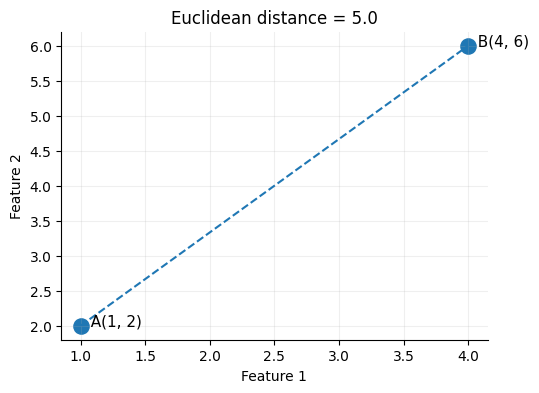

In [2]:
A, B = np.array([1, 2]), np.array([4, 6])
distance = np.linalg.norm(A - B)
print(f'A={A}, B={B}, Euclidean distance={distance:.1f}')

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter([A[0], B[0]], [A[1], B[1]], s=120)
ax.plot([A[0], B[0]], [A[1], B[1]], '--', lw=1.5)
for p, name in [(A, 'A'), (B, 'B')]:
  ax.annotate(f'  {name}({p[0]}, {p[1]})', p, fontsize=11)
ax.set(xlabel='Feature 1', ylabel='Feature 2', title=f'Euclidean distance = {distance:.1f}')
plt.show()
assert np.isclose(distance, 5.0)

### 2.2 Four broad clustering families

| Family | Core idea | Example | Typical strength or limitation |
|---|---|---|---|
| **Partitioning** | Assign observations to a fixed number of groups | K-Means | Efficient, but tends to prefer compact, roughly convex groups |
| **Hierarchical** | Build a nested grouping hierarchy | Agglomerative | Can inspect levels; linkage choice matters |
| **Density-based** | Connect observations in dense regions | DBSCAN | Handles irregular shapes and can flag noise; sensitive to density parameters |
| **Model-based** | Model clusters as probability distributions | Gaussian mixture | Soft probabilities; requires distributional assumptions |

**Demonstration:** The same algorithm will not necessarily recognize three very different shapes.

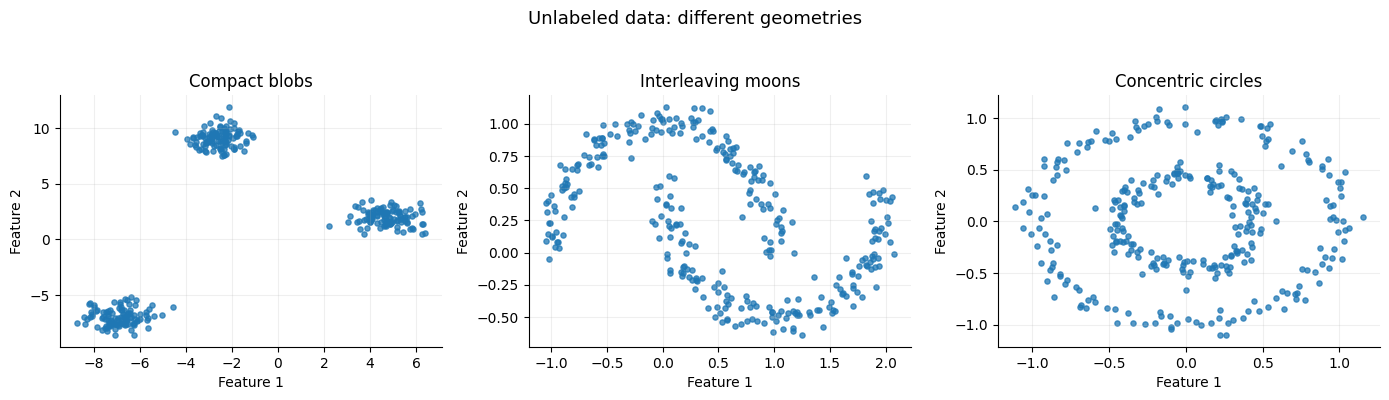

In [3]:
shape_sets = {
    'Compact blobs': make_blobs(n_samples=320, centers=3, cluster_std=0.75, random_state=RANDOM_STATE)[0],
    'Interleaving moons': make_moons(n_samples=320, noise=0.07, random_state=RANDOM_STATE)[0],
    'Concentric circles': make_circles(n_samples=320, noise=0.06, factor=0.45, random_state=RANDOM_STATE)[0],
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, X_shape) in zip(axes, shape_sets.items()):
    ax.scatter(X_shape[:, 0], X_shape[:, 1], s=14, alpha=0.75)
    ax.set(title=name, xlabel='Feature 1', ylabel='Feature 2')
plt.suptitle('Unlabeled data: different geometries', y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

### 2.3 Which algorithm works on non-convex shapes?

We standardize the `make_moons` data and compare **K-Means**, **Agglomerative clustering** (single linkage), and **DBSCAN**. The purpose is to compare geometric assumptions—not to claim that any algorithm wins on all datasets.

DBSCAN uses `-1` to mark samples treated as **noise**. Its `eps` parameter is a neighborhood radius, **not** the number of clusters.

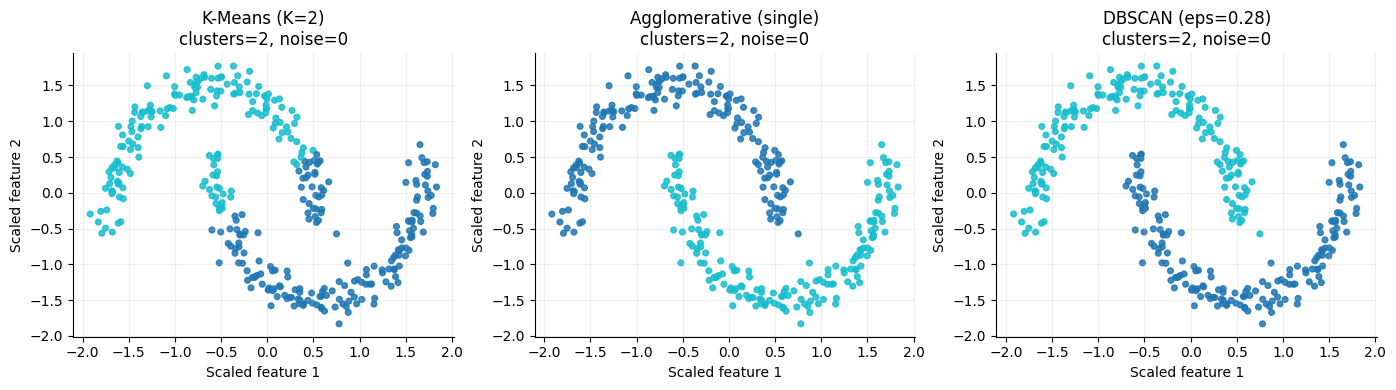

In [4]:
X_moons, _ = make_moons(n_samples=360, noise=0.07, random_state=RANDOM_STATE)
X_moons = StandardScaler().fit_transform(X_moons)
comparison_models = {
    'K-Means (K=2)': KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE),
    'Agglomerative (single)': AgglomerativeClustering(n_clusters=2, linkage='single'),
    'DBSCAN (eps=0.28)': DBSCAN(eps=0.28, min_samples=5),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
for ax, (name, model) in zip(axes, comparison_models.items()):
    labels = model.fit_predict(X_moons)
    clusters = len(set(labels) - {-1})
    noise = int(np.sum(labels == -1))
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap='tab10', s=17, alpha=0.85)
    ax.set(title=f'{name}\nclusters={clusters}, noise={noise}', xlabel='Scaled feature 1', ylabel='Scaled feature 2')
plt.tight_layout()
plt.show()

> **Takeaway:** Clustering is not just about selecting $K$: it also requires selecting an appropriate **similarity notion and algorithm family**.

## 3. K-Means: from mathematics to implementation

K-Means repeatedly performs two steps:

1. **Assignment:** assign every observation to its nearest centroid $\mu_k$.
2. **Update:** replace each centroid by the arithmetic mean of observations assigned to it.

Its objective (also called **inertia** or within-cluster sum of squares) is

$$J=\sum_{k=1}^{K}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^2.$$

K-Means seeks a **local minimum** of this objective: different initial centroid choices can give different answers, so multiple initializations (`n_init`) are useful. It is affected by distance scaling and outliers.

### 3.1 Calculate one iteration by hand

Take four points $P_1=(1,1),P_2=(1,2),P_3=(5,5),P_4=(6,5)$ and initial centroids $\mu_1=(1,1),\mu_2=(6,5)$. Assign each point, then average within each group. The following cell does both operations transparently.

Distances to the two original centers:


,To mu_1,To mu_2
P1,0.000,6.403
P2,1.000,5.831
P3,5.657,1.000
P4,6.403,0.000


Assignments (0-based): [0, 0, 1, 1]
Updated centers: [[1.0, 1.5], [5.5, 5.0]]


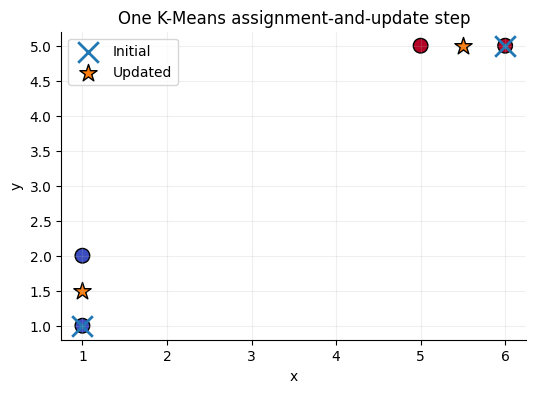

In [5]:
points = np.array([[1., 1.], [1., 2.], [5., 5.], [6., 5.]])
initial_centers = np.array([[1., 1.], [6., 5.]])
distances = np.linalg.norm(points[:, None, :] - initial_centers[None, :, :], axis=2)
manual_labels = distances.argmin(axis=1)
updated_centers = np.vstack([points[manual_labels == k].mean(axis=0) for k in range(2)])
print('Distances to the two original centers:')
display(pd.DataFrame(distances.round(3), columns=['To mu_1', 'To mu_2'], index=['P1','P2','P3','P4']))
print('Assignments (0-based):', manual_labels.tolist())
print('Updated centers:', updated_centers.tolist())
assert np.allclose(updated_centers, [[1, 1.5], [5.5, 5]])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(points[:, 0], points[:, 1], c=manual_labels, cmap='coolwarm', s=110, edgecolor='black')
ax.scatter(initial_centers[:, 0], initial_centers[:, 1], s=220, marker='x', linewidths=2, label='Initial')
ax.scatter(updated_centers[:, 0], updated_centers[:, 1], s=170, marker='*', edgecolor='black', label='Updated')
ax.set(title='One K-Means assignment-and-update step', xlabel='x', ylabel='y')
ax.legend()
plt.show()

### 3.2 Case study: Movie preferences

**Problem:** We know six viewers and their preferences for four movies (scores from 1 to 5), but we have **no labeled customer segments**. Can we discover two patterns of preference?

*Features:* `[Jaws, Star Wars, Exorcist, Omen]`. **Rows = people; columns = numeric ratings.** The `user` column is a name for interpretation and must **not** be sent to K-Means.

**Predict:** Which people look similar *before* fitting the model? Do the first two film ratings and last two ratings reveal opposite tastes?

,user,Jaws,Star Wars,Exorcist,Omen
0,john,5,5,2,1
1,mary,4,5,3,2
2,bob,4,4,4,3
3,lisa,2,2,4,5
4,lee,1,2,3,4
5,harry,2,1,5,5


Numerical matrix shape: (6, 4)


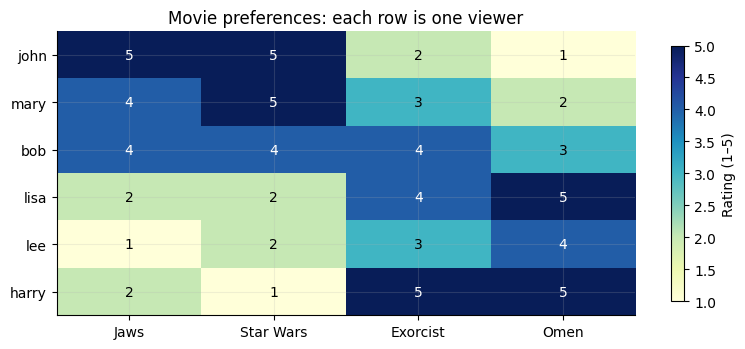

In [6]:
# Reconstructed from https://cse.msu.edu/~ptan/dmbook/tutorials/tutorial8/tutorial8.html
movie_ratings = pd.DataFrame([
    ['john',  5, 5, 2, 1],
    ['mary',  4, 5, 3, 2],
    ['bob',   4, 4, 4, 3],
    ['lisa',  2, 2, 4, 5],
    ['lee',   1, 2, 3, 4],
    ['harry', 2, 1, 5, 5],
], columns=['user', 'Jaws', 'Star Wars', 'Exorcist', 'Omen'])
movie_features = ['Jaws', 'Star Wars', 'Exorcist', 'Omen']
X_movies = movie_ratings[movie_features]  # Numeric feature matrix (shape: 6 × 4)
display(movie_ratings)
print('Numerical matrix shape:', X_movies.shape)

fig, ax = plt.subplots(figsize=(8, 3.6))
heat = ax.imshow(X_movies.to_numpy(), vmin=1, vmax=5, cmap='YlGnBu', aspect='auto')
ax.set(yticks=np.arange(len(movie_ratings)), yticklabels=movie_ratings['user'],
       xticks=np.arange(4), xticklabels=movie_features, title='Movie preferences: each row is one viewer')
for row in range(len(movie_ratings)):
    for col in range(4):
        ax.text(col, row, str(X_movies.iat[row, col]), ha='center', va='center',
                color='white' if X_movies.iat[row, col] >= 4 else 'black')
plt.colorbar(heat, ax=ax, label='Rating (1–5)', shrink=0.9)
plt.tight_layout()
plt.show()

### 3.3 Fit K-Means and **interpret** the centers

We set $K=2$ as a **hypothesis**: perhaps two taste profiles exist. K-Means does *not* know what movie genres are; it simply groups four-dimensional rating vectors by squared Euclidean distances.

**Centroid calculation, worked example:** If `john`, `mary`, and `bob` form one group, the mean ratings are

$$\mu_A=\left(\frac{5+4+4}{3},\frac{5+5+4}{3},\frac{2+3+4}{3},\frac{1+2+3}{3}\right)=(4.33,4.67,3.00,2.00).$$

For `lisa`, `lee`, and `harry`, the mean is $(1.67,1.67,4.00,4.67)$.

These centers summarize the *average preferences* of the assigned viewers. **IDs 0 and 1 are arbitrary**: a different run or version could swap their numerical names without changing the grouping.

Viewer membership:


,user,cluster
0,bob,0
1,john,0
2,mary,0
3,harry,1
4,lee,1
5,lisa,1


Cluster centroids (average ratings):


,Jaws,Star Wars,Exorcist,Omen
cluster,,,,
0,4.33,4.67,3.0,2.00
1,1.67,1.67,4.0,4.67


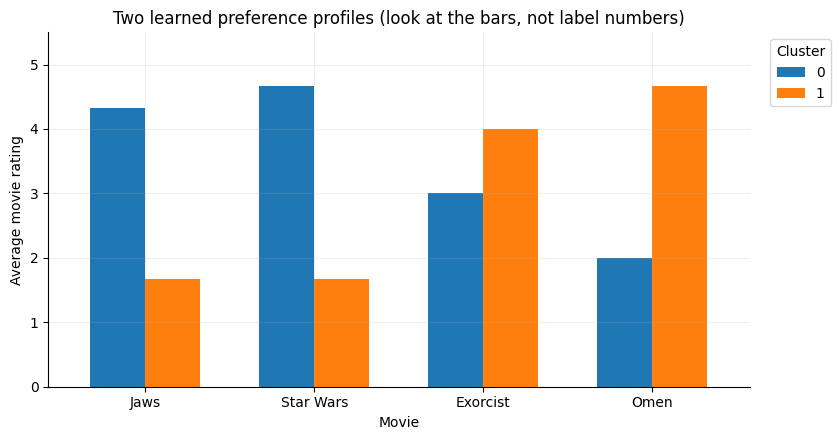

In [7]:
movie_model = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE)
movie_clusters = movie_model.fit_predict(X_movies)
movie_assignments = movie_ratings[['user']].copy()
movie_assignments['cluster'] = movie_clusters
movie_centers = pd.DataFrame(movie_model.cluster_centers_, columns=movie_features)
movie_centers.index.name = 'cluster'
print('Viewer membership:')
display(movie_assignments.sort_values(['cluster', 'user']).reset_index(drop=True))
print('Cluster centroids (average ratings):')
display(movie_centers.round(2))

ax = movie_centers.T.plot(kind='bar', figsize=(8.5, 4.5), rot=0, width=0.65)
ax.set(ylabel='Average movie rating', xlabel='Movie', ylim=(0, 5.5),
       title='Two learned preference profiles (look at the bars, not label numbers)')
ax.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# This should group the first three vs the last three viewers; IDs can swap.
assert len(set(movie_clusters[:3])) == 1
assert len(set(movie_clusters[3:])) == 1
assert movie_clusters[0] != movie_clusters[3]

### 3.4 Assign a **new** viewer to an existing cluster

A trained K-Means model can map a new rating vector to its **nearest centroid**. This is not a supervised classification of a known 'genre preference' label: it is an extension of the learned grouping.

For example, new user `paul` has ratings `(4,5,1,2)`. The algorithm compares Paul's four-dimensional vector against each learned center and chooses the one with the **smaller Euclidean distance**.

**Question:** How would you interpret a person whose ratings fall nearly halfway between the two centers?

In [8]:
# Five unseen viewers from the MSU example.
new_viewers = pd.DataFrame([
    ['paul', 4, 5, 1, 2],
    ['kim',  3, 2, 4, 4],
    ['liz',  2, 3, 4, 1],
    ['tom',  3, 2, 3, 3],
    ['bill', 5, 4, 1, 4],
], columns=['user'] + movie_features)
predictions = movie_model.predict(new_viewers[movie_features])
centroid_distances = movie_model.transform(new_viewers[movie_features])
new_viewers['assigned_cluster'] = predictions
new_viewers['nearest_centroid_distance'] = centroid_distances.min(axis=1).round(2)
display(new_viewers)
print('Notice: K-Means *must* assign each viewer to a cluster; there is no built-in uncertainty or rejection threshold.')

,user,Jaws,Star Wars,Exorcist,Omen,assigned_cluster,nearest_centroid_distance
0,paul,4,5,1,2,0,2.05
1,kim,3,2,4,4,1,1.53
2,liz,2,3,4,1,0,3.20
3,tom,3,2,3,3,1,2.38
4,bill,5,4,1,4,0,2.98


Notice: K-Means *must* assign each viewer to a cluster; there is no built-in uncertainty or rejection threshold.


**Critical transition — why use another dataset for validation?**

The six-person movie example is ideal for explaining *features, distance, centroid updates, and predictions*, but it is **too small** for a reliable search over many numbers of clusters. For $K=6$, inertia can reach zero because every user becomes their own cluster! Moreover, Silhouette and Davies–Bouldin cannot evaluate the single-cluster solution, and Silhouette is undefined when every point has a unique label.

We now use a larger, still unlabeled, **synthetic two-dimensional dataset**. It makes the behavior of K-Means and model-selection criteria easier to see. The plotted colors are algorithm assignments, not ground-truth classes.

### 3.5 Create a larger dataset and hide the answer

We generate four underlying groups for instructional purposes, then discard those generating labels. **The clustering algorithm sees only the feature matrix**, not the true group assignments. We standardize the observations so distance is not driven by units.

Data shape: (480, 2) (samples, features)


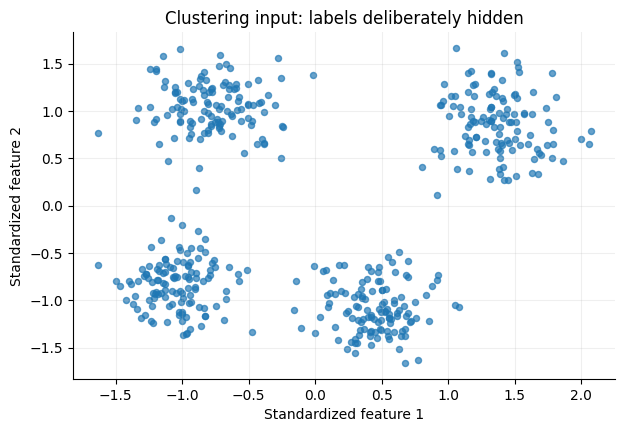

In [9]:
X_raw, _ = make_blobs(
    n_samples=480,
    centers=[[-6, -3], [-5, 5], [1, -4], [5, 4]],
    cluster_std=[1.1, 1.2, 1.1, 1.35],
    random_state=RANDOM_STATE,
)
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
print('Data shape:', X.shape, '(samples, features)')
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X[:, 0], X[:, 1], s=19, alpha=0.68)
ax.set(title='Clustering input: labels deliberately hidden', xlabel='Standardized feature 1', ylabel='Standardized feature 2')
plt.show()

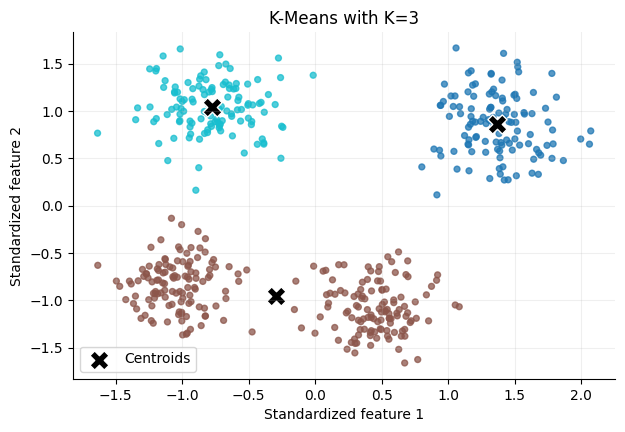

Inertia (WCSS): 201.65


In [10]:
initial_k = 3
kmeans_3 = KMeans(n_clusters=initial_k, n_init=10, random_state=RANDOM_STATE)
labels_3 = kmeans_3.fit_predict(X)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=labels_3, cmap='tab10', s=18, alpha=0.75)
ax.scatter(kmeans_3.cluster_centers_[:, 0], kmeans_3.cluster_centers_[:, 1],
           c='black', s=190, marker='X', edgecolors='white', linewidths=1, label='Centroids')
ax.set(title=f'K-Means with K={initial_k}', xlabel='Standardized feature 1', ylabel='Standardized feature 2')
ax.legend()
plt.show()
print('Inertia (WCSS):', round(kmeans_3.inertia_, 2))

### 3.6 Change K and observe the result

**Underfitting:** Too few clusters may merge visibly different groups.  
**Overfragmentation:** Too many clusters can split coherent groups into artificial smaller groups.

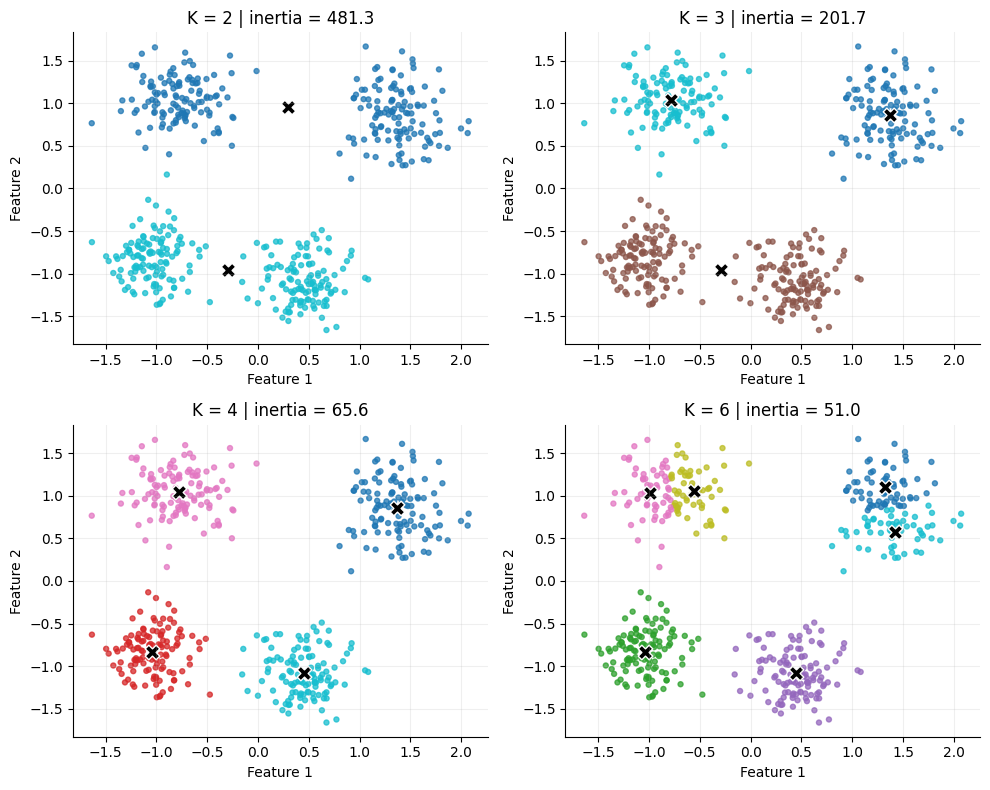

In [11]:
K_CHOICES = [2, 3, 4, 6]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, k in zip(axes.flat, K_CHOICES):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    lab = model.fit_predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=lab, cmap='tab10', s=13, alpha=0.75)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
               c='black', marker='X', s=110, edgecolors='white')
    ax.set(title=f'K = {k} | inertia = {model.inertia_:.1f}', xlabel='Feature 1', ylabel='Feature 2')
plt.tight_layout()
plt.show()

> **Predict before computing:** Which of $K=2,3,4,6$ would you choose by eye? What would count as independent evidence for that choice?  
> **Transition:** The number of clusters is unknown in real applications; let's compare it systematically rather than trusting a plot alone.

## 4. Cluster validation and model selection

These are **internal validation** approaches: they inspect the data and predicted grouping, **not hidden ground-truth labels**. They do not prove that clusters correspond to real-world categories.

| Method | What it looks at | Preferred direction | Requirement / limitation |
|---|---|---|---|
| **Elbow (inertia)** | Within-cluster squared error | Look for a **bend** | Inertia decreases as $K$ grows; bend can be ambiguous |
| **Silhouette** | Cohesion versus separation | **Higher** is generally better | Needs at least two clusters; can favor compact separation |
| **Davies–Bouldin** | Cluster dispersion relative to center distance | **Lower** is generally better | Centroid-based, less suitable for unusual geometries |

### 4.1 Elbow Method

$$\mathrm{WCSS}(K)=\sum_{k=1}^K\sum_{x_i\in C_k}\|x_i-\mu_k\|^2.$$

As $K$ increases, the model has more centroids and can usually decrease WCSS. **Do not choose the largest tested $K$ just because inertia is smallest.** Instead, ask where each extra centroid starts bringing only a small improvement.

### 4.2 Compute all scores with consistent settings

We evaluate **the same fitted K-Means solutions** for each $K$, so differences in scores do not come from changing the dataset or random seed. Inertia is defined at $K=1$; Silhouette and Davies–Bouldin are not, so those begin at $K=2$.

We store the full fitted models in a dictionary to avoid silently refitting with different random initializations later.

In [12]:
MAX_K = 10
models = {}
records = []
for k in range(1, MAX_K + 1):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    models[k] = model
    records.append({
        'K': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(X, labels) if k >= 2 else np.nan,
        'Davies-Bouldin': davies_bouldin_score(X, labels) if k >= 2 else np.nan,
    })
results = pd.DataFrame(records).set_index('K')
display(results.round(4))
assert results.shape[0] == 10
assert results.loc[1, ['Silhouette', 'Davies-Bouldin']].isna().all()

,Inertia,Silhouette,Davies-Bouldin
K,,,
1,960.0000,NaN,NaN
2,481.3497,0.5033,0.9612
3,201.6516,0.6336,0.5252
4,65.5729,0.7254,0.3662
5,56.8475,0.6323,0.6370
6,51.0257,0.5225,0.8845
7,45.2823,0.4407,1.0051
8,40.6033,0.3522,1.1150
9,36.7301,0.3578,1.0387


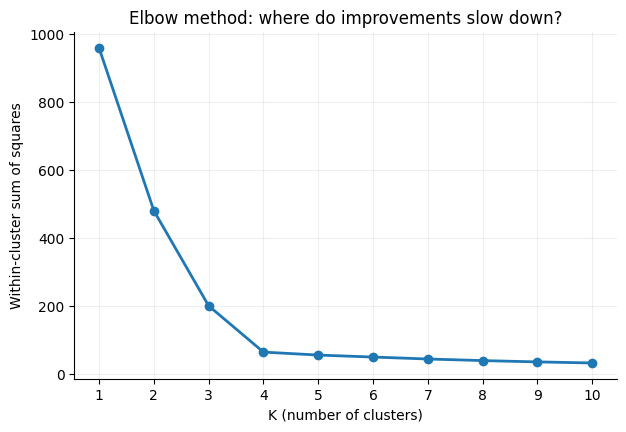

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(results.index, results['Inertia'], 'o-', linewidth=2, markersize=6)
ax.set(xticks=results.index, xlabel='K (number of clusters)',
       ylabel='Within-cluster sum of squares', title='Elbow method: where do improvements slow down?')
plt.show()

### 4.3 Silhouette Score: cohesion vs separation

For observation $i$:

- $a(i)$ = average distance from $i$ to the **other points in its own cluster** (**cohesion**).
- $b(i)$ = **smallest** average distance from $i$ to points in any **other** cluster (**nearest competing cluster**).

$$s(i)=\frac{b(i)-a(i)}{\max(a(i), b(i))},\qquad -1\le s(i)\le 1.$$

The dataset's Silhouette Score is the mean of $s(i)$ across observations.

**Numerical example:** If $a(i)=2$ and $b(i)=6$, then $s(i)=(6-2)/6=0.667$. This is positive because the point is closer, on average, to its own cluster. If $a=5,b=3$, the score is $(3-5)/5=-0.4$: another cluster may suit it better.

**Interpretation:** Values near +1 indicate better separation; near 0 suggest a boundary; negative values indicate possible mismatch. A universally correct cutoff (e.g., “score > 0.5 means excellent”) does **not** exist.

a(i)=2, b(i)=6 => silhouette=0.667
a(i)=5, b(i)=3 => silhouette=-0.400


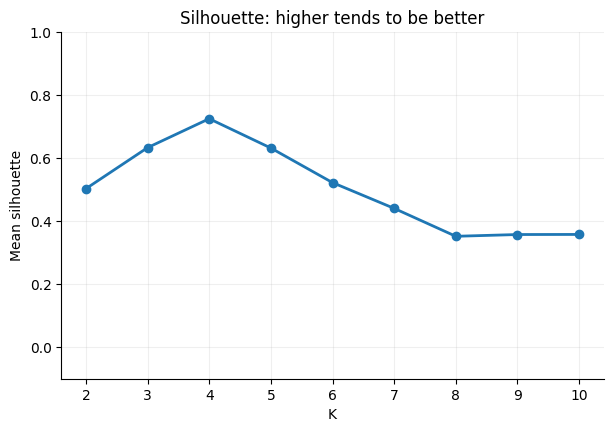

In [14]:
for own, other in [(2, 6), (5, 3)]:
    score = (other - own) / max(own, other)
    print(f'a(i)={own}, b(i)={other} => silhouette={score:.3f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(results.index[1:], results['Silhouette'].iloc[1:], 'o-', linewidth=2)
ax.set(xticks=results.index[1:], ylim=(-0.1, 1), xlabel='K', ylabel='Mean silhouette',
       title='Silhouette: higher tends to be better')
plt.show()

### 4.4 Davies–Bouldin Index: compactness vs center separation

For a pair of clusters $i,j$:

- $S_i$ = average Euclidean distance of points in cluster $i$ from their centroid (**dispersion**).
- $M_{ij}$ = Euclidean distance between cluster centroids $i$ and $j$.
- $R_{ij}=(S_i+S_j)/M_{ij}$ = their **similarity ratio** (smaller is better).

$$\mathrm{DB}=\frac{1}{K}\sum_{i=1}^{K}\max_{j\ne i}\left(\frac{S_i+S_j}{M_{ij}}\right).$$

**Numerical example (two clusters):** If $S_1=1$, $S_2=1.5$, and $M_{12}=5$, then $R_{12}=2.5/5=0.5$. Smaller within-cluster scatter or larger separation lowers the ratio.

**Model selection:** For comparable solutions on the same representation, **lower DB is generally better**. It does *not* have a fixed upper limit, and it is not a probability.

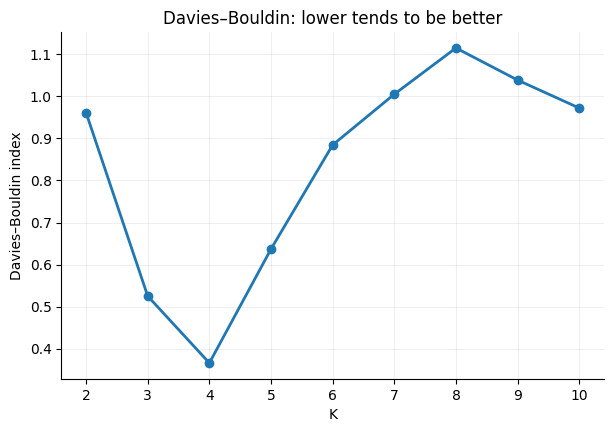

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(results.index[1:], results['Davies-Bouldin'].iloc[1:], 'o-', linewidth=2)
ax.set(xticks=results.index[1:], xlabel='K', ylabel='Davies–Bouldin index',
       title='Davies–Bouldin: lower tends to be better')
plt.show()

### 4.5 Side-by-side model selection dashboard

**Think critically:** The three criteria are *not* optimized in identical ways. Inertia always benefits from extra centroids, and the other metrics can disagree. Treat them as **evidence**, not as an automatic truth oracle.

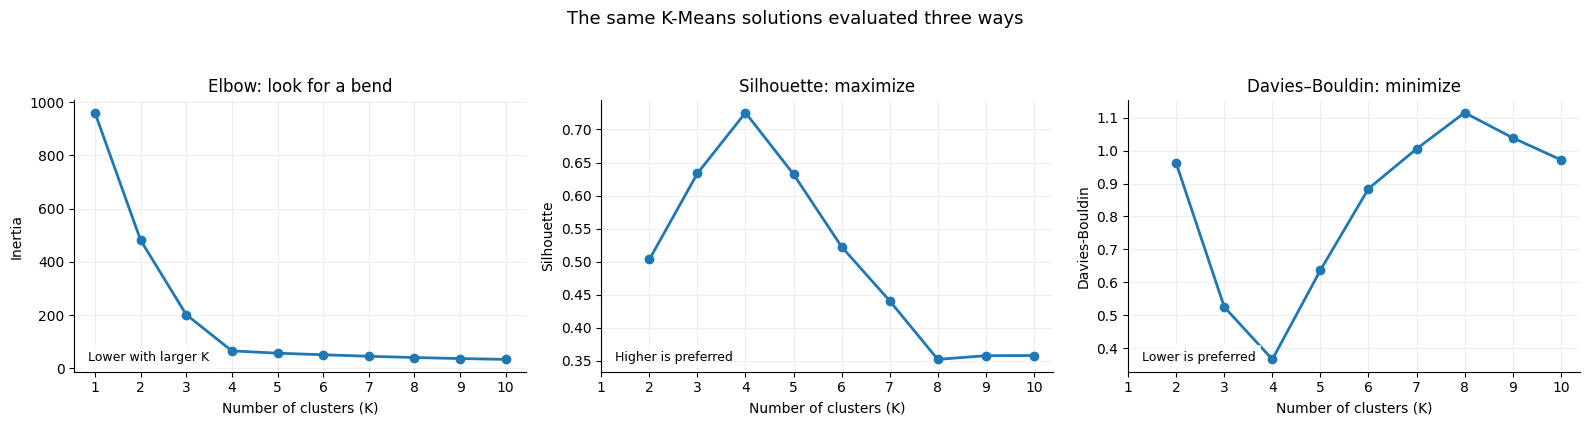

Maximum silhouette occurs at K=4 (0.725)
Minimum Davies–Bouldin occurs at K=4 (0.366)
Elbow is a visual judgment; do not replace it with simply minimizing inertia.


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.0))
settings = [
    ('Inertia', 'Elbow: look for a bend', 'Lower with larger K'),
    ('Silhouette', 'Silhouette: maximize', 'Higher is preferred'),
    ('Davies-Bouldin', 'Davies–Bouldin: minimize', 'Lower is preferred'),
]
for ax, (column, title, subtitle) in zip(axes, settings):
    scores = results[column].dropna()
    ax.plot(scores.index, scores.values, 'o-', linewidth=2)
    ax.set(xlabel='Number of clusters (K)', ylabel=column, title=title, xticks=results.index)
    ax.text(0.03, 0.03, subtitle, transform=ax.transAxes, fontsize=9, va='bottom',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.8})
plt.suptitle('The same K-Means solutions evaluated three ways', fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

best_sil_k = int(results['Silhouette'].idxmax())
best_db_k = int(results['Davies-Bouldin'].idxmin())
print(f'Maximum silhouette occurs at K={best_sil_k} ({results.loc[best_sil_k, "Silhouette"]:.3f})')
print(f'Minimum Davies–Bouldin occurs at K={best_db_k} ({results.loc[best_db_k, "Davies-Bouldin"]:.3f})')
print('Elbow is a visual judgment; do not replace it with simply minimizing inertia.')

## 5. Association rule mining

**Different from clustering:** We are no longer grouping observations; we are finding **frequent co-occurrence patterns** in transactions.

An association rule has the form $A\Rightarrow B$, where $A$ and $B$ are disjoint sets of items. For example, `{Milk} → {Bread}`.

For $N$ transactions:

$$\mathrm{support}(A\Rightarrow B)=P(A\cap B)=\frac{\#(A\cup B)}{N}$$
$$\mathrm{confidence}(A\Rightarrow B)=P(B\mid A)=\frac{P(A\cap B)}{P(A)}$$
$$\mathrm{lift}(A\Rightarrow B)=\frac{P(B\mid A)}{P(B)}.$$

- **Support:** How frequently do both itemsets appear?
- **Confidence:** Among transactions containing $A$, how often is $B$ also present?
- **Lift:** Is the rule more common than expected from the baseline frequency of $B$? (`> 1` positive co-occurrence, `= 1` independence, `< 1` negative co-occurrence).

**Warning:** Association does not establish causation. A frequent consequent can produce high confidence even when lift is weak.

In [18]:
# Simple synthetic supermarket baskets: same data in the explanation and calculations.
transactions = [
    {'Milk', 'Bread', 'Butter'},  # T1
    {'Milk', 'Bread'},            # T2
    {'Bread', 'Butter'},          # T3
    {'Eggs', 'Coffee'},           # T4
    {'Milk', 'Bread', 'Butter'},  # T5
    {'Bread', 'Butter'},          # T6
    {'Milk', 'Bread'},            # T7
    {'Milk', 'Bread', 'Eggs'},    # T8
    {'Eggs', 'Coffee'},           # T9
    {'Milk', 'Butter'},           # T10
    {'Bread', 'Butter', 'Eggs'},  # T11
    {'Milk', 'Bread', 'Butter'},  # T12
]
N = len(transactions)
transaction_table = pd.DataFrame([
    {'Transaction': f'T{i+1}', 'Items': ', '.join(sorted(t))}
    for i, t in enumerate(transactions)
])
display(transaction_table)

def support(itemset):
    target = set(itemset)
    return sum(target.issubset(t) for t in transactions) / N

A, B = {'Milk'}, {'Bread'}
support_ab = support(A | B)
confidence_ab = support_ab / support(A)
lift_ab = confidence_ab / support(B)
print(f'Milk => Bread | support={support_ab:.3f}, confidence={confidence_ab:.3f}, lift={lift_ab:.3f}')

,Transaction,Items
0,T1,"Bread, Butter, Milk"
1,T2,"Bread, Milk"
2,T3,"Bread, Butter"
3,T4,"Coffee, Eggs"
4,T5,"Bread, Butter, Milk"
5,T6,"Bread, Butter"
6,T7,"Bread, Milk"
7,T8,"Bread, Eggs, Milk"
8,T9,"Coffee, Eggs"
9,T10,"Butter, Milk"


Milk => Bread | support=0.500, confidence=0.857, lift=1.143


### 5.1 Apriori: frequent itemsets first, rules second

**Apriori property:** If an itemset is frequent, **all its nonempty subsets must also be frequent**. Conversely, if a candidate subset is infrequent, any superset containing it can be skipped.

In [32]:
def apriori_small(transactions, min_support=0.16, max_len=3):
    """Educational Apriori for small sets of Python sets (not optimized for scale)."""
    transactions = [frozenset(t) for t in transactions]
    n = len(transactions)
    unique_items = sorted(set().union(*transactions))
    candidates = {frozenset([item]) for item in unique_items}
    previous_frequent = set()
    rows = []
    for size in range(1, max_len + 1):
        if size > 1:
            # Join frequent (size-1)-itemsets and prune if a subset is infrequent.
            candidates = {
                a | b for a in previous_frequent for b in previous_frequent
                if len(a | b) == size
                and all(frozenset(s) in previous_frequent for s in combinations(a | b, size - 1))
            }
        current_frequent = set()
        for candidate in sorted(candidates, key=lambda x: sorted(x)):
            count = sum(candidate.issubset(t) for t in transactions)
            relative_frequency = count / n
            if relative_frequency >= min_support:
                current_frequent.add(candidate)
                rows.append({'itemset': candidate, 'size': size,
                             'count': count, 'support': relative_frequency})
        previous_frequent = current_frequent
        if not previous_frequent:
            break
    return pd.DataFrame(rows, columns=['itemset', 'size', 'count', 'support'])

frequent = apriori_small(transactions, min_support=0.16, max_len=3)
frequent_display = frequent.copy()
frequent_display['itemset'] = frequent_display['itemset'].map(lambda x: ', '.join(sorted(x)))
display(frequent_display.sort_values(['size', 'support'], ascending=[True, False]).reset_index(drop=True).round(3))
assert len(frequent) > 0

,itemset,size,count,support
0,Bread,1,9,0.750
1,Butter,1,7,0.583
2,Milk,1,7,0.583
3,Eggs,1,4,0.333
4,Coffee,1,2,0.167
5,"Bread, Butter",2,6,0.500
6,"Bread, Milk",2,6,0.500
7,"Butter, Milk",2,4,0.333
8,"Bread, Eggs",2,2,0.167
9,"Coffee, Eggs",2,2,0.167


In [33]:
def rules_from_frequent_itemsets(frequent, min_confidence=0.60):
    """Generate rules A=>B and scores from Apriori output."""
    support_lookup = dict(zip(frequent['itemset'], frequent['support']))
    rows = []
    for union_items in frequent['itemset']:
        if len(union_items) < 2:
            continue
        for ante_size in range(1, len(union_items)):
            for antecedent_tuple in combinations(sorted(union_items), ante_size):
                antecedent = frozenset(antecedent_tuple)
                consequent = union_items - antecedent
                confidence = support_lookup[union_items] / support_lookup[antecedent]
                lift = confidence / support_lookup[consequent]
                if confidence >= min_confidence:
                    rows.append({
                        'antecedent': ', '.join(sorted(antecedent)),
                        'consequent': ', '.join(sorted(consequent)),
                        'support': support_lookup[union_items],
                        'confidence': confidence,
                        'lift': lift,
                    })
    return pd.DataFrame(rows).sort_values(['lift', 'confidence'], ascending=False).reset_index(drop=True)

rules = rules_from_frequent_itemsets(frequent, min_confidence=0.60)
display(rules.round(3))
assert not rules.empty
print('Rule with the highest lift:', rules.loc[0, 'antecedent'], '=>', rules.loc[0, 'consequent'])
print('Interpret rules descriptively; do not mistake co-occurrence for causation.')

,antecedent,consequent,support,confidence,lift
0,Coffee,Eggs,0.167,1.000,3.000
1,Butter,Bread,0.500,0.857,1.143
2,Milk,Bread,0.500,0.857,1.143
3,Bread,Butter,0.500,0.667,1.143
4,Bread,Milk,0.500,0.667,1.143
5,"Butter, Milk",Bread,0.250,0.750,1.000


Rule with the highest lift: Coffee => Eggs
Interpret rules descriptively; do not mistake co-occurrence for causation.


> Is `{Eggs} → {Coffee}` necessarily stronger than `{Milk} → {Bread}` in every business sense? Consider **support**, **confidence**, **lift**, and how few transactions contain coffee.  
> **Takeaway:** Rare rules can have high lift but low support. Threshold selection and sample size matter.

## 6. Dimensionality reduction with PCA

Suppose each observation has $d=13$ attributes. We want a 2D view, while losing as little overall variance as possible under a **linear projection**.

Principal Component Analysis (PCA):

1. Center the data and usually **standardize** features if their scales differ.
2. Find mutually orthogonal axes (**principal components**) that explain decreasing amounts of variance.
3. Project observations onto the top $m$ axes: $Z=X_{\mathrm{centered}}W_m$.

**PCA does not use class labels to learn components**; it is unsupervised. Principal components are linear combinations of original features and may be harder to interpret. PCA preserves variance, **not guaranteed cluster separation**.

The built-in Wine dataset has 13 numeric features and known cultivar classes. We **do not use class labels to train PCA**; we color the final scatterplot by class purely to evaluate what the visualization reveals.

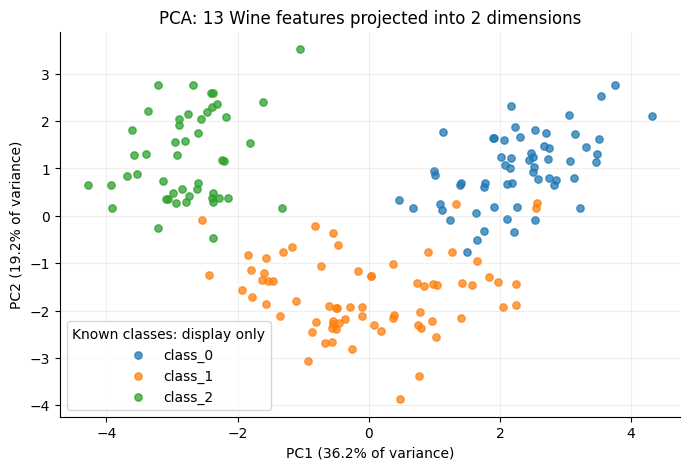

Original: (178, 13) → Projected: (178, 2)


In [34]:
wine = load_wine()
X_wine = wine.data
y_wine = wine.target  # only used for post-hoc coloring, NEVER passed to PCA
X_wine_scaled = StandardScaler().fit_transform(X_wine)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_wine = pca.fit_transform(X_wine_scaled)

fig, ax = plt.subplots(figsize=(8, 5))
for cls in np.unique(y_wine):
    mask = (y_wine == cls)
    ax.scatter(Z_wine[mask, 0], Z_wine[mask, 1], s=28, alpha=0.75,
               label=wine.target_names[cls])
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)',
       ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)',
       title='PCA: 13 Wine features projected into 2 dimensions')
ax.legend(title='Known classes: display only')
plt.show()
print('Original:', X_wine_scaled.shape, '→ Projected:', Z_wine.shape)
assert Z_wine.shape == (178, 2)

### 6.1 How much information (variance) does PCA retain?

The **explained variance ratio** of each component is its fraction of the total variance in the scaled data. Summing ratios over the first $m$ components tells us how much of the total variance those components represent.

“80% variance retained” does **not** mean “80% clustering accuracy retained.”

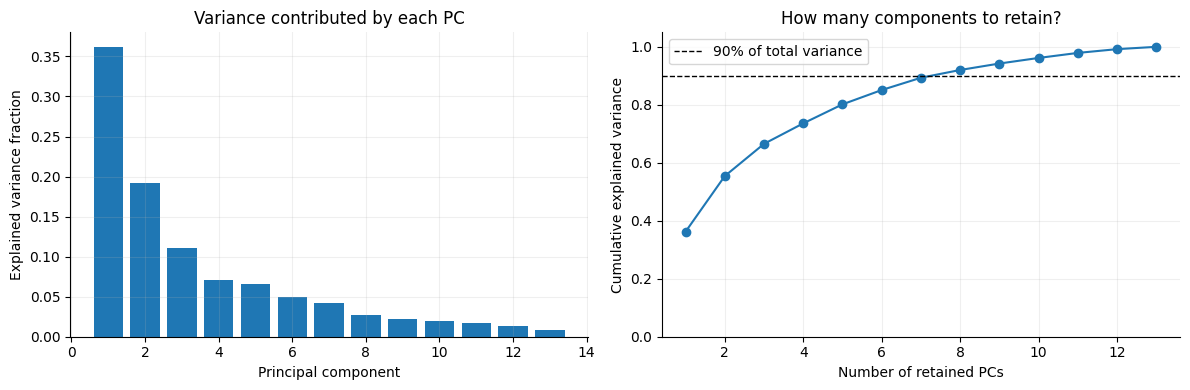

Top 2 PCs retain 55.4% of standardized-data variance.
PCs required to reach at least 90%: 8 of 13


In [35]:
pca_full = PCA().fit(X_wine_scaled)
variance_ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(variance_ratio)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(variance_ratio) + 1), variance_ratio)
axes[0].set(xlabel='Principal component', ylabel='Explained variance fraction',
            title='Variance contributed by each PC')
axes[1].plot(range(1, len(cumulative) + 1), cumulative, 'o-')
axes[1].axhline(0.90, color='black', linestyle='--', lw=1, label='90% of total variance')
axes[1].set(xlabel='Number of retained PCs', ylabel='Cumulative explained variance',
            title='How many components to retain?', ylim=(0, 1.05))
axes[1].legend()
plt.tight_layout()
plt.show()
num_for_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print(f'Top 2 PCs retain {cumulative[1]:.1%} of standardized-data variance.')
print(f'PCs required to reach at least 90%: {num_for_90} of {X_wine_scaled.shape[1]}')

## 7. Applications, recap, and questions

| Method | Practical application | Question to ask before deploying |
|---|---|---|
| Clustering | Customer segmentation, document grouping, anomaly exploration | What defines *similarity* and are groups meaningful? |
| Cluster validation | Choosing $K$ or comparing K-Means configurations | Do scores align with shape, stability, and business needs? |
| Association rules | Market baskets, event co-occurrence | Does a rule have sufficient support and actionable lift? |
| PCA / dimensionality reduction | Feature compression, exploratory visualization | Is the lost variance acceptable for the downstream task? |

### Quick quiz (answer before revealing or checking instructor notes)

1. Why can't we choose $K$ simply by minimizing inertia?
2. What does a *negative* silhouette value suggest?
3. Between Davies–Bouldin indices 0.45 and 1.2, which is preferred **all else equal**?
4. How is a clustering task different from association-rule mining?
5. Can PCA guarantee that the best-separated groups remain best-separated in 2D?

*Unsupervised learning identifies patterns without target labels, but the discovered structure must be carefully validated and interpreted.*

---
## 7. Hierarchical clustering with vertebrates

Each row records six binary attributes, plus an animal name and a reference animal class.

- Only the six binary attributes are passed to clustering; `Name` and `Class` are **excluded**.
- Agglomerative clustering merges objects based on linkage distance. **Single linkage** uses the closest cross-group pair; **complete** uses the farthest; **average** uses the average cross-group distance.
- The **dendrogram** records which observations merge and at what distance. Its leaves can be cut at a desired height to suggest clusters; it does not prove that these groups must match the reference classes.
- Caution: two different animals can have identical binary features; grouping is restricted to what the feature matrix captures.

In [37]:
vertebrate_columns = ['Name', 'Warm-blooded', 'Gives Birth', 'Aquatic Creature',
                     'Aerial Creature', 'Has Legs', 'Hibernates', 'Class']
vertebrate_rows = [
    ['human', 1,1,0,0,1,0,'mammals'],
    ['python', 0,0,0,0,0,1,'reptiles'],
    ['salmon', 0,0,1,0,0,0,'fishes'],
    ['whale', 1,1,1,0,0,0,'mammals'],
    ['frog', 0,0,1,0,1,1,'amphibians'],
    ['komodo', 0,0,0,0,1,0,'reptiles'],
    ['bat', 1,1,0,1,1,1,'mammals'],
    ['pigeon', 1,0,0,1,1,0,'birds'],
    ['cat', 1,1,0,0,1,0,'mammals'],
    ['leopard shark', 0,1,1,0,0,0,'fishes'],
    ['turtle', 0,0,1,0,1,0,'reptiles'],
    ['penguin', 1,0,1,0,1,0,'birds'],
    ['porcupine', 1,1,0,0,1,1,'mammals'],
    ['eel', 0,0,1,0,0,0,'fishes'],
    ['salamander', 0,0,1,0,1,1,'amphibians'],
]
vertebrates = pd.DataFrame(vertebrate_rows, columns=vertebrate_columns)
display(vertebrates)
vertebrate_X = vertebrates.drop(columns=['Name', 'Class']).to_numpy(dtype=float)
print('Clustering features:', vertebrate_X.shape)
assert vertebrate_X.shape == (15, 6)

,Name,Warm-blooded,Gives Birth,Aquatic Creature,Aerial Creature,Has Legs,Hibernates,Class
0,human,1,1,0,0,1,0,mammals
1,python,0,0,0,0,0,1,reptiles
2,salmon,0,0,1,0,0,0,fishes
3,whale,1,1,1,0,0,0,mammals
4,frog,0,0,1,0,1,1,amphibians
5,komodo,0,0,0,0,1,0,reptiles
6,bat,1,1,0,1,1,1,mammals
7,pigeon,1,0,0,1,1,0,birds
8,cat,1,1,0,0,1,0,mammals
9,leopard shark,0,1,1,0,0,0,fishes


Clustering features: (15, 6)


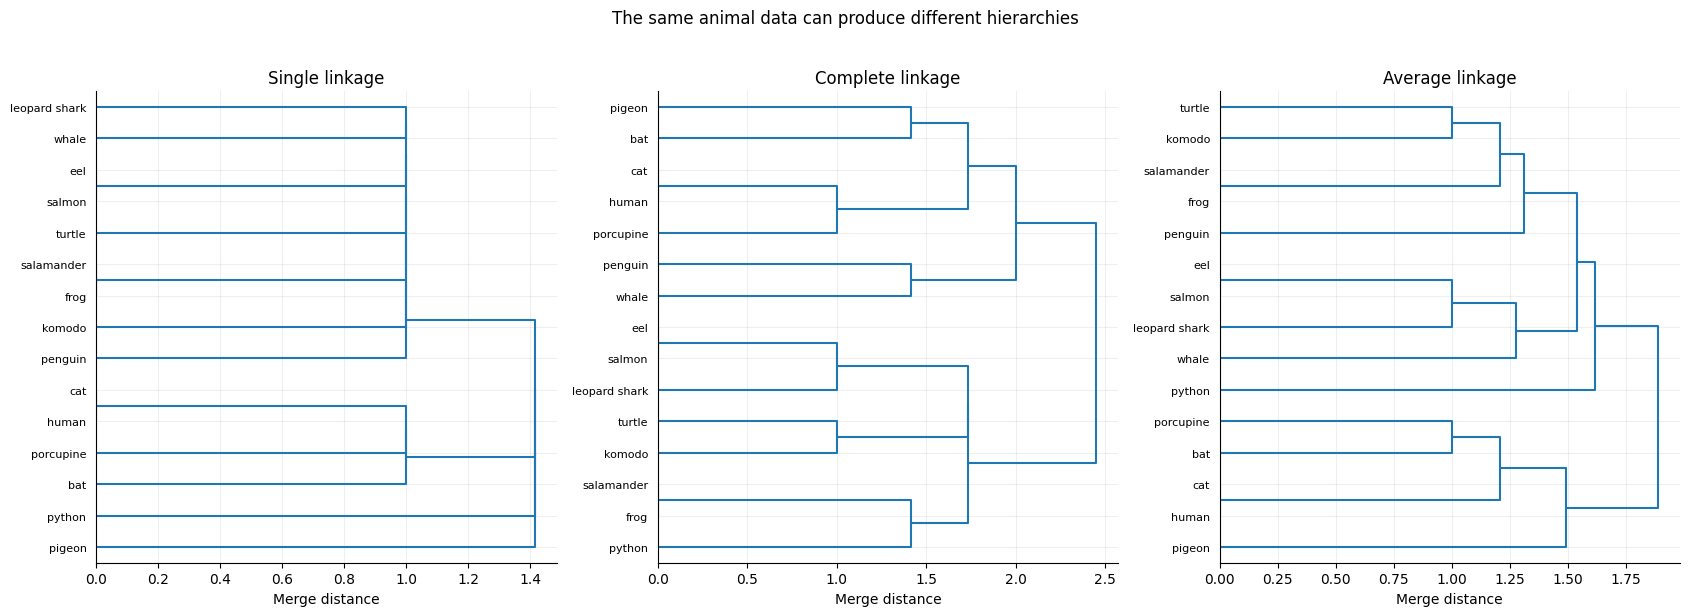

Compare: Which animals merge immediately? Which linkages create long chains?


In [38]:
from scipy.cluster.hierarchy import linkage, dendrogram
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, link in zip(axes, ['single', 'complete', 'average']):
    Z = linkage(vertebrate_X, method=link, metric='euclidean')
    dendrogram(Z, labels=vertebrates['Name'].tolist(), orientation='right', ax=ax,
               leaf_font_size=8, color_threshold=0)
    ax.set(title=f'{link.title()} linkage', xlabel='Merge distance')
plt.suptitle('The same animal data can produce different hierarchies', y=1.02)
plt.tight_layout()
plt.show()
print('Compare: Which animals merge immediately? Which linkages create long chains?')